# G8 — : préparation de GTSDB

## 1.Récupérer le code

In [7]:
# Récupérer le projet depuis GitHub
%cd /kaggle/working

!git clone https://github.com/salmaaz29/g8-traffic-sign-detection.git

/kaggle/working
Cloning into 'g8-traffic-sign-detection'...
remote: Enumerating objects: 23, done.
remote: Counting objects: 100% (23/23), done.
remote: Compressing objects: 100% (20/20), done.
remote: Total 23 (delta 0), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (23/23), 12.03 KiB | 4.01 MiB/s, done.


In [8]:
%cd /kaggle/working/g8-traffic-sign-detection

!ls

/kaggle/working/g8-traffic-sign-detection
config.yaml  notebooks	README.md  reports  requirements.txt  scripts  src


In [9]:
!pip install -r requirements.txt

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 28.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 99.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 122.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [ultralytics] [ultralytics]platform]


pytorch torchvision ultralytics opencv albumentation streamlit

In [10]:
%cd /kaggle/working/g8-traffic-sign-detection

/kaggle/working/g8-traffic-sign-detection


## 3. Vérifier les annotations (`visualize_gt.py`)
Si gt.txt est dans un dossier zippé, dézippez-le d'abord dans `/kaggle/working/gtsdb_raw` puis mettez ce chemin dans `RAW`.

gt.txt : /kaggle/input/datasets/safabouguezzi/german-traffic-sign-detection-benchmark-gtsdb/TrainIJCNN2013/TrainIJCNN2013/gt.txt
600 images, 506 images annotées, 852 panneaux
Mosaïque enregistrée : /kaggle/working/g8-traffic-sign-detection/reports/gt_check.png


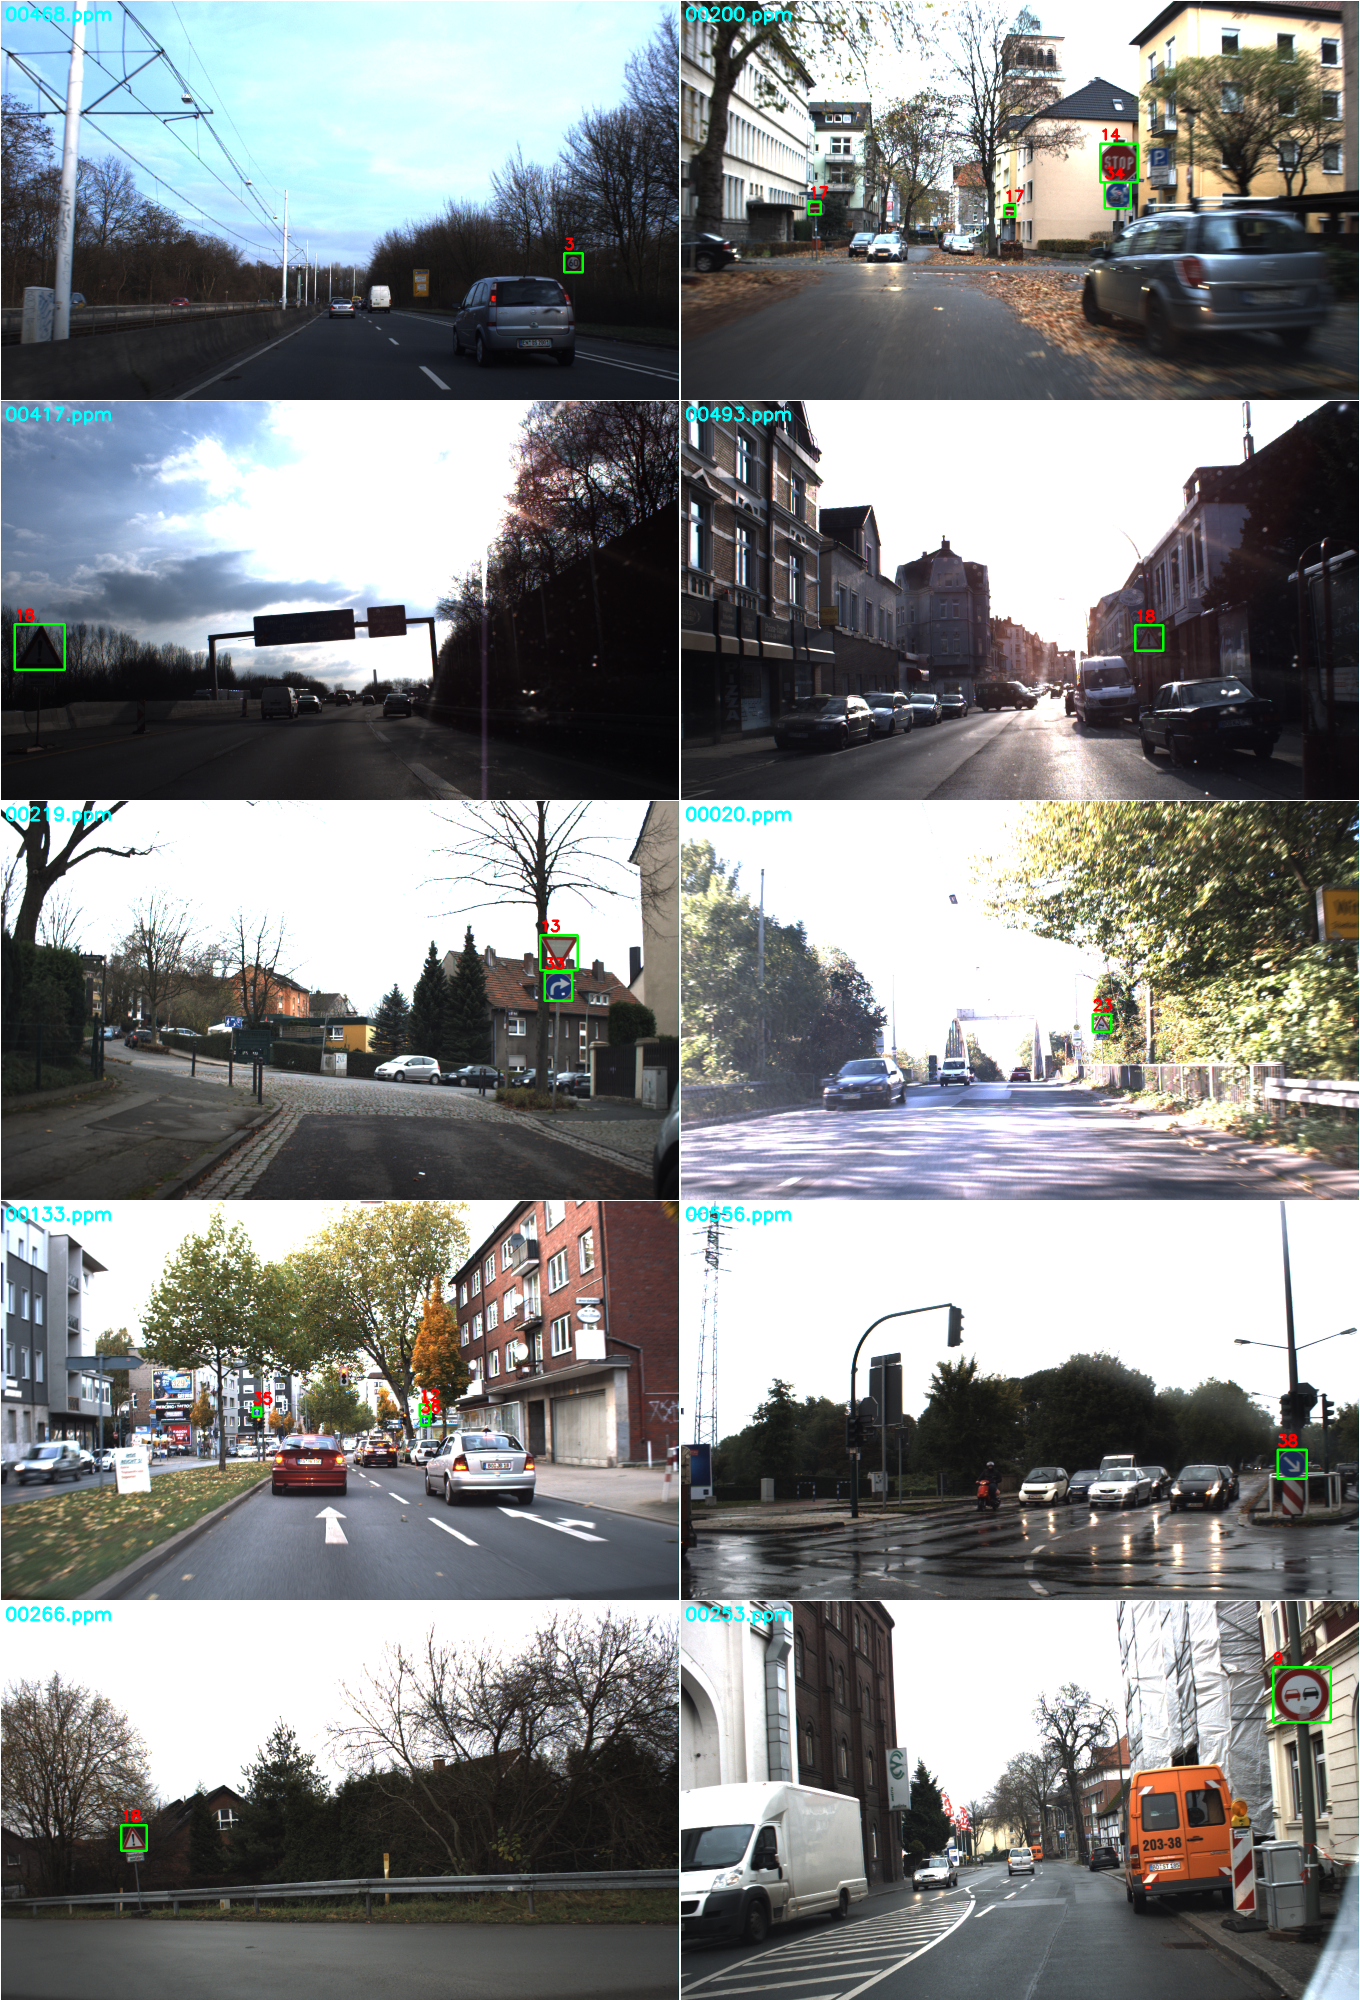

In [11]:
RAW = '/kaggle/input'   # ou '/kaggle/working/gtsdb_raw' si vous avez dû dézipper
!python scripts/visualize_gt.py --raw {RAW}
from IPython.display import Image, display
display(Image('reports/gt_check.png'))

**Contrôle** : les rectangles verts doivent bien entourer les panneaux.
Son rôle est de :
1. Lire les images du dataset GTSDB.
2. Lire le fichier d'annotations gt.txt.
3. Identifier les panneaux de signalisation dans les images.
4. Dessiner des rectangles (Bounding Boxes) autour des panneaux.
5. Générer une image de vérification dans reports/gt_check.png.

## 4. Conversion YOLO + COCO avec split fixe

Cette commande sert à convertir le dataset GTSDB brut en un dataset préparé et organisé pour entraîner ton modèle YOLO avec 4 classes de panneaux de signalisation.

In [14]:
%%writefile src/data/convert_gtsdb.py
"""
Conversion GTSDB -> YOLO (YOLO11, RT-DETR) + COCO JSON (Faster R-CNN)
avec split FIXE (sauvegardé dans splits/split.json).

Deux cas gérés automatiquement :
  - dataset complet (900 images annotées) : train/val = images 0..599, test = 600..899
  - TrainIJCNN2013 seul (600 images)      : split 70 / 15 / 15 par blocs d'images consécutives

Usage :
    python -m src.data.convert_gtsdb --mode 4cls --raw /kaggle/input
"""
import argparse
import json
import random
from pathlib import Path

import cv2
from tqdm import tqdm

from src.data.classes import get_class_names, map_class
from src.data.gtsdb import find_gt, list_images, parse_gt
from src.utils import ROOT, load_config


def _chunks(names, block):
    return [names[i:i + block] for i in range(0, len(names), block)]


def _flat(blocks):
    return sorted(n for b in blocks for n in b)


def make_split(names, last_idx, val_ratio, block, seed,
               val_ratio_no_test=0.15, test_ratio_no_test=0.15):
    names = sorted(names)  # stems : "00000", "00001", ...
    trainval = [n for n in names if int(n) <= last_idx]
    test = [n for n in names if int(n) > last_idx]
    rng = random.Random(seed)

    # blocs d'images consécutives : on évite que des images quasi identiques
    # (même séquence) se retrouvent dans deux sous-ensembles différents
    if test:  # dataset complet : le test officiel existe
        blocks = _chunks(trainval, block)
        rng.shuffle(blocks)
        n_val = round(len(blocks) * val_ratio)
        return {"train": _flat(blocks[n_val:]), "val": _flat(blocks[:n_val]),
                "test": sorted(test)}

    # pas de test officiel annoté (TrainIJCNN2013 seul) : split 3 voies
    blocks = _chunks(names, block)
    rng.shuffle(blocks)
    n_val = round(len(blocks) * val_ratio_no_test)
    n_test = round(len(blocks) * test_ratio_no_test)
    return {"train": _flat(blocks[n_val + n_test:]),
            "val": _flat(blocks[:n_val]),
            "test": _flat(blocks[n_val:n_val + n_test])}


def main():
    cfg = load_config()
    ap = argparse.ArgumentParser()
    ap.add_argument("--mode", default=cfg["dataset"]["mode"], choices=["4cls", "43cls"])
    ap.add_argument("--raw", default=None, help="dossier du dataset (ex: /kaggle/input)")
    ap.add_argument("--processed", default=None, help="dossier de sortie")
    args = ap.parse_args()
    mode = args.mode

    gt_path = find_gt(args.raw or ROOT / cfg["paths"]["raw"])
    raw = gt_path.parent
    print("gt.txt trouvé :", gt_path)
    out = Path(args.processed or ROOT / cfg["paths"]["processed"]) / f"gtsdb_{mode}"
    split_path = ROOT / cfg["paths"]["split"]

    files = list_images(raw)          # {stem: nom_fichier}
    assert files, f"Aucune image (.ppm/.png/.jpg) dans {raw}"
    print(f"{len(files)} images trouvées")
    names = list(files)
    ann = parse_gt(gt_path)
    class_names = get_class_names(mode)

    # --- split fixe : créé une fois, puis relu (sauf s'il n'a pas de test) ---
    split = None
    if split_path.exists():
        split = json.loads(split_path.read_text())
        if not split.get("test"):
            print("Ancien split sans images de test -> recréé.")
            split = None
        else:
            print(f"Split existant relu : {split_path}")
    if split is None:
        d = cfg["dataset"]
        split = make_split(names, d["train_val_last_index"], d["val_ratio"],
                           d["block_size"], cfg["seed"],
                           d.get("val_ratio_no_test", 0.15), d.get("test_ratio_no_test", 0.15))
        split_path.parent.mkdir(parents=True, exist_ok=True)
        split_path.write_text(json.dumps(split, indent=1))
        print(f"Split créé : {split_path}")
    print({k: len(v) for k, v in split.items()})
    assert not (set(split["train"]) & set(split["val"]) | set(split["train"]) & set(split["test"])
                | set(split["val"]) & set(split["test"])), "Fuite entre sous-ensembles !"

    coco_dir = out / "coco"
    coco_dir.mkdir(parents=True, exist_ok=True)

    for sp, split_files in split.items():
        img_dir = out / "images" / sp
        lbl_dir = out / "labels" / sp
        img_dir.mkdir(parents=True, exist_ok=True)
        lbl_dir.mkdir(parents=True, exist_ok=True)

        # supprime les fichiers d'un ancien split (évite les images dans le mauvais dossier)
        keep = set(split_files)
        for f in list(img_dir.glob("*.png")) + list(lbl_dir.glob("*.txt")):
            if f.stem not in keep:
                f.unlink()

        coco = {
            "images": [], "annotations": [],
            # id = index + 1 (0 est réservé au fond pour Faster R-CNN)
            "categories": [{"id": i + 1, "name": n} for i, n in enumerate(class_names)],
        }
        ann_id = 1
        for img_id, stem in enumerate(tqdm(split_files, desc=sp), start=1):
            img = cv2.imread(str(raw / files[stem]))
            h, w = img.shape[:2]
            dst = img_dir / f"{stem}.png"
            if not dst.exists():
                cv2.imwrite(str(dst), img)  # PNG : sans perte (Ultralytics ne lit pas .ppm)

            coco["images"].append({"id": img_id, "file_name": f"{stem}.png",
                                   "width": w, "height": h})
            lines = []
            for x1, y1, x2, y2, c in ann.get(stem, []):
                x1, y1 = max(0, x1), max(0, y1)
                x2, y2 = min(w, x2), min(h, y2)
                bw, bh = x2 - x1, y2 - y1
                if bw <= 1 or bh <= 1:
                    continue
                k = map_class(c, mode)
                lines.append(f"{k} {(x1 + bw / 2) / w:.6f} {(y1 + bh / 2) / h:.6f} "
                             f"{bw / w:.6f} {bh / h:.6f}")
                coco["annotations"].append({
                    "id": ann_id, "image_id": img_id, "category_id": k + 1,
                    "bbox": [x1, y1, bw, bh], "area": bw * bh, "iscrowd": 0,
                    "orig_class": c,
                })
                ann_id += 1
            (lbl_dir / f"{stem}.txt").write_text("\n".join(lines))

        (coco_dir / f"{sp}.json").write_text(json.dumps(coco))

    yaml_txt = f"path: {out.resolve().as_posix()}\ntrain: images/train\nval: images/val\ntest: images/test\nnames:\n"
    yaml_txt += "".join(f"  {i}: {n}\n" for i, n in enumerate(class_names))
    (out / "dataset.yaml").write_text(yaml_txt)
    print(f"Terminé -> {out}\nYOLO : {out/'dataset.yaml'}\nCOCO : {coco_dir}")


if __name__ == "__main__":
    main()


Overwriting src/data/convert_gtsdb.py


In [16]:
import os

split_path = "splits/split.json"

if os.path.exists(split_path):
    os.remove(split_path)
    print("Ancien split supprimé.")

Ancien split supprimé.


In [17]:
RAW = "/kaggle/input"

!python -m src.data.convert_gtsdb --mode 4cls --raw {RAW}

gt.txt trouvé : /kaggle/input/datasets/safabouguezzi/german-traffic-sign-detection-benchmark-gtsdb/TrainIJCNN2013/TrainIJCNN2013/gt.txt
600 images trouvées
Split créé : /kaggle/working/g8-traffic-sign-detection/splits/split.json
{'train': 420, 'val': 90, 'test': 90}
test: 100%|█████████████████████████████████████| 90/90 [00:04<00:00, 18.11it/s]
Terminé -> /kaggle/working/g8-traffic-sign-detection/data/processed/gtsdb_4cls
YOLO : /kaggle/working/g8-traffic-sign-detection/data/processed/gtsdb_4cls/dataset.yaml
COCO : /kaggle/working/g8-traffic-sign-detection/data/processed/gtsdb_4cls/coco


## 5. Vérifications

vérifier que la conversion du dataset s'est bien déroulée, avant de passer à l'entraînement du modèle YOLO.

In [18]:
import json, glob, os
split = json.load(open('splits/split.json'))
print({k: len(v) for k, v in split.items()})   # attendu : 420 / 90 / 90

{'train': 420, 'val': 90, 'test': 90}


In [19]:
base = 'data/processed/gtsdb_4cls'
for sp in ['train', 'val', 'test']:
    n_img = len(glob.glob(f'{base}/images/{sp}/*.png'))
    n_lbl = sum(1 for f in glob.glob(f'{base}/labels/{sp}/*.txt') if os.path.getsize(f) > 0)
    coco = json.load(open(f'{base}/coco/{sp}.json'))
    print(sp, '| images:', n_img, '| images avec panneaux:', n_lbl, '| boîtes COCO:', len(coco['annotations']))
print(open(f'{base}/dataset.yaml').read())

train | images: 420 | images avec panneaux: 361 | boîtes COCO: 589
val | images: 90 | images avec panneaux: 62 | boîtes COCO: 113
test | images: 90 | images avec panneaux: 83 | boîtes COCO: 150
path: /kaggle/working/g8-traffic-sign-detection/data/processed/gtsdb_4cls
train: images/train
val: images/val
test: images/test
names:
  0: prohibitory
  1: danger
  2: mandatory
  3: other



Train : 361 images contiennent des panneaux et 59 sont sans panneau.



Validation : 62 images contiennent des panneaux et 28 sont sans panneau.



Test : 83 images contiennent des panneaux et 7 sont sans panneau.

## 6. Sauvegarder
- Téléchargez `splits/split.json` (panneau *Output*, ou la cellule ci-dessous) et **committez-le** dans le dépôt.
- Cliquez sur **Save Version > Save & Run All (Commit)** : les données converties deviennent un *Output* réutilisable comme *Input* dans vos notebooks d'entraînement.